# Daten anaylse (Analyse der Einflussgrößen)
- Welche Variablen beeinflussen Bodenatmung (soil.res) .

In [1]:
hainich.data <- read.csv("hainich.csv", sep=";")
#str(hainich.data)
#summary(hainich.data)
head(hainich.data)



,soil.res,temp.0,temp.5,temp.10,temp.15,smoi,lmoi,litter.d,ph.litter,ph.soil0,⋯,litno3,litnh4,litdoc,sno30,snh40,sdoc0,sno35,snh45,sdoc5,nn
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,4.3750,15.52,11.91,11.79,11.74,41.75939,0.6782141,0.3,6.45,4.23,⋯,0.036393668,0.018885578,0.4684278,0.01070368,0.002945600,0.09095835,0.004000000,0.003130156,0.11875886,2.49
2,4.3425,11.75,11.54,11.41,11.40,32.72151,0.5684457,1.5,6.42,4.30,⋯,0.002000000,0.003346766,0.3854520,0.00500000,0.003632943,0.08783729,0.004000000,0.001853513,0.05462559,1.06
3,2.9800,12.61,11.75,11.52,11.48,33.83690,0.6595609,1.0,6.32,4.27,⋯,0.017632441,0.004607981,0.3919999,0.01760351,0.002377711,0.06770848,0.014260353,0.002639287,0.04153205,1.58
4,2.5625,11.75,11.40,11.35,11.26,28.25263,0.5779671,1.5,5.74,3.90,⋯,0.016701030,0.006571442,0.3751276,0.01089270,0.002118255,0.09349080,0.013633983,0.002255407,0.05857811,1.36
5,2.6000,12.29,11.59,11.45,11.39,42.87905,0.6757647,1.5,6.24,4.05,⋯,0.007461533,0.010068415,0.5004978,0.02276019,0.008599232,0.06802427,0.014321943,0.001674059,0.04704889,2.77
6,6.2125,12.93,11.74,11.59,11.50,27.27465,0.6292582,2.0,5.54,4.23,⋯,0.038616580,0.017991253,0.7431942,0.01743749,0.008957436,0.08329230,0.006601767,0.001000000,0.05974198,1.60


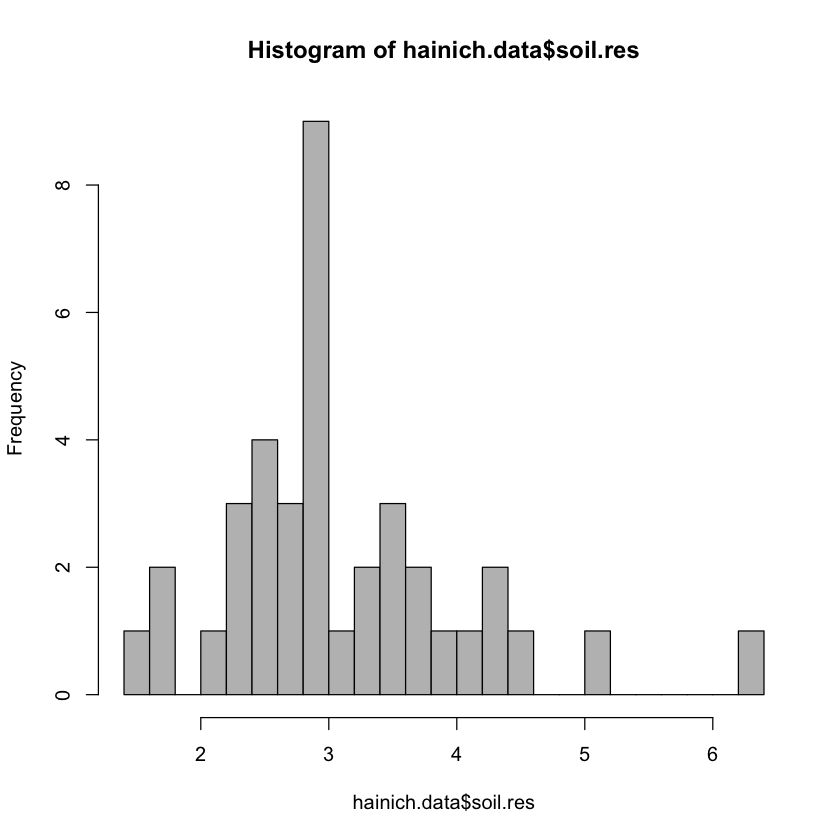

[1] 3.113026

[1] 2.9225

[1] 0.9041724

[1] 8.541006

[1] 0.3054519

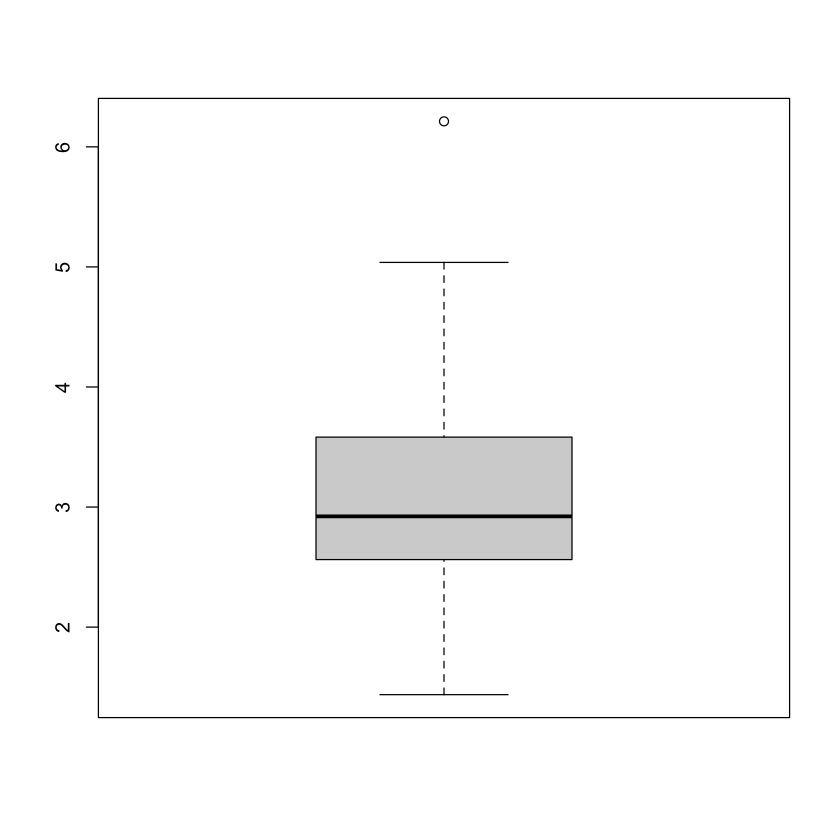

In [2]:
hist(hainich.data$soil.res, breaks=20, col="grey")
boxplot(hainich.data$soil.res)
mean(hainich.data$soil.res)
median(hainich.data$soil.res)
var(hainich.data$soil.res)
median(hainich.data$soil.res)^2

#Varianzkoeff
sd(hainich.data$soil.res) / mean(hainich.data$soil.res) # 0.305 -> moderate sreung
# Varianz ist viel kleiner als Median^2

Histogramm
- keine Gleichverteilung
- keine starke normakverteilung abeeer annährend glockenforme?
- mögliche ausreßer rechts?????
Boxplot
- Median ≈ 2.9 -3
- Die mittleren 50% der Werte liegen ungefähr zwischen 2.6 und 3.6
- Es gibt einige größere Werte (rechts) → mögliche hohe Bodenatmung

- Daten sind:
    - leicht rechts-schief (Die meisten Werte links/mittig aber einige großere werte weit rechts), mean> median -> rechts-schief
    - Streuung moderat, 
    - Paar hohe Werte könnten ökologisch wichtig sein?

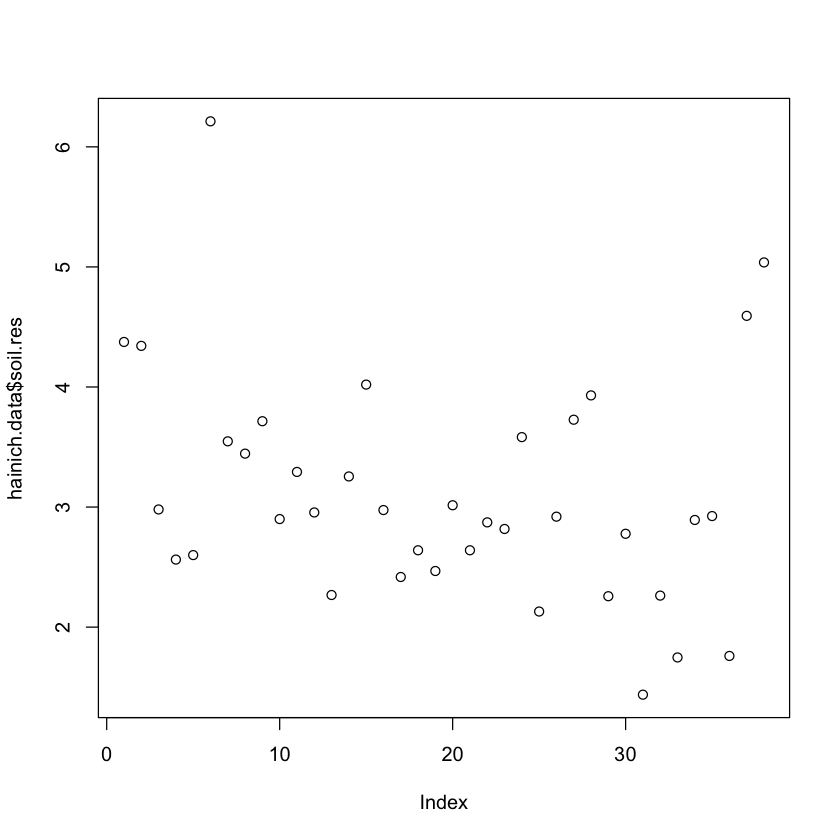

In [ ]:
#Varianz überprufen
plot(hainich.data$soil.res)


### Normalverteilung
-> nicht normalverteilt

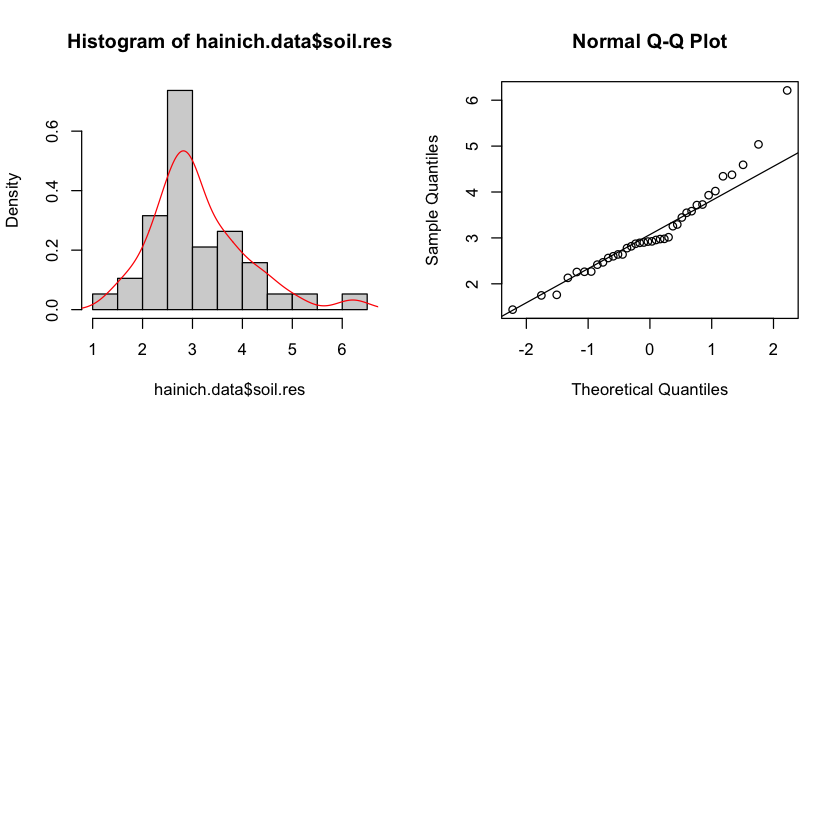

In [ ]:
par(mfrow=c(2,2))
#Test aud normalverteilung
hist(hainich.data$soil.res, prob=TRUE)
lines(density(hainich.data$soil.res), col="red")

qqnorm(hainich.data$soil.res)
qqline(hainich.data$soil.res)
#nope nicht perf normal

### Transformation der Daten

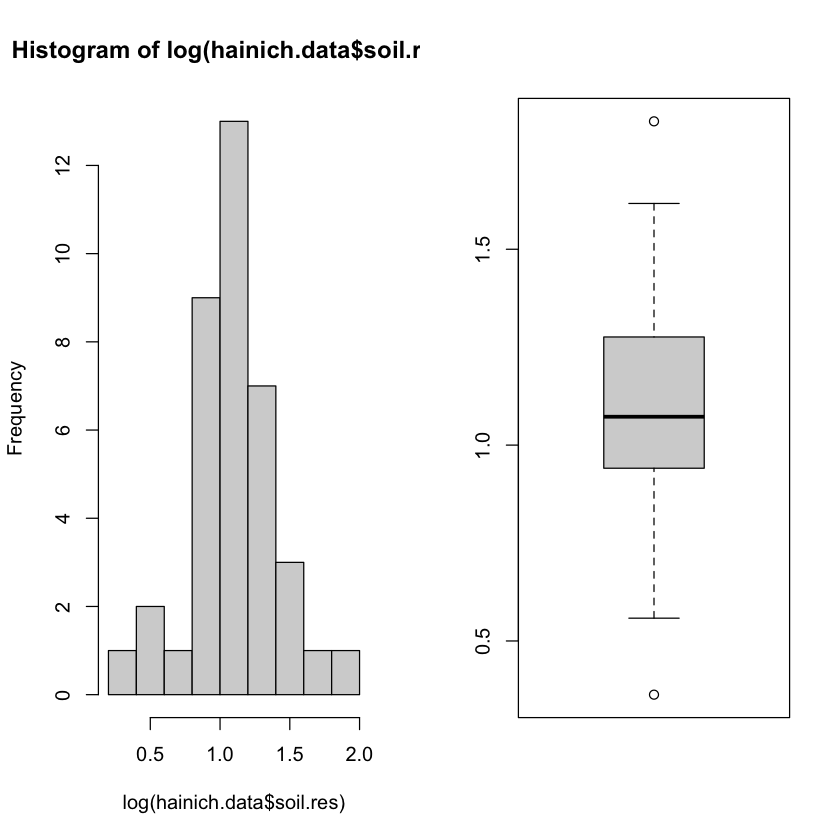

In [ ]:
par(mfrow=c(1,2))
hist(log(hainich.data$soil.res))
boxplot(log(hainich.data$soil.res))

- log transf reduziert schiefe
- Median etwa in der Mitte der Box → symmetrisch

sqrt tranfs -> no

### Lognormal- vert
Punkte liegen deutlich näher an der Linie -> besser!

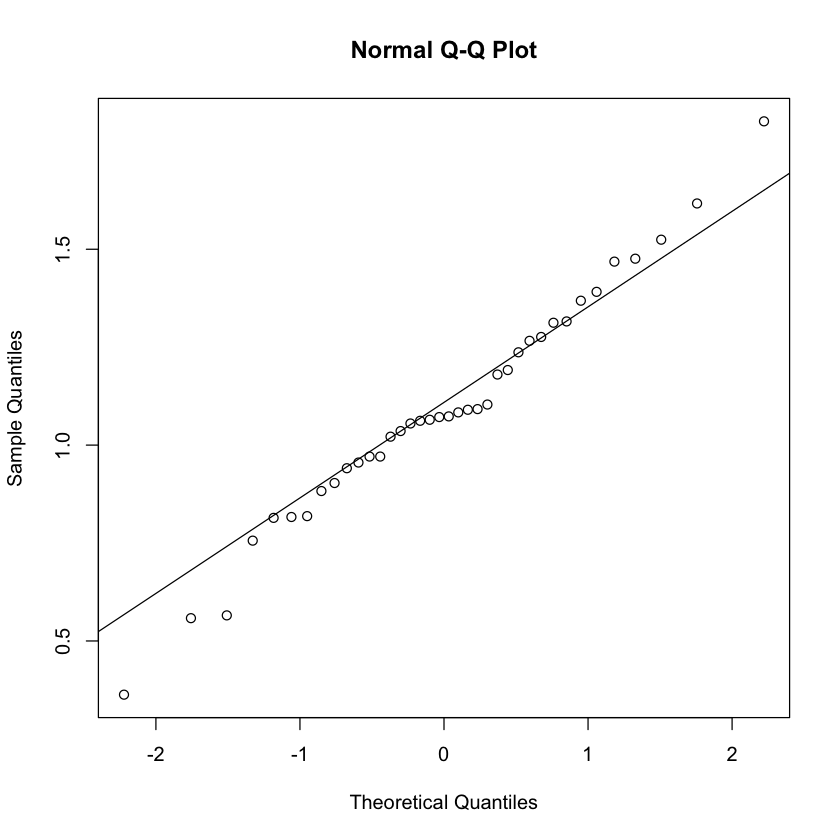

In [ ]:
qqnorm(log(hainich.data$soil.res))
qqline(log(hainich.data$soil.res))



## Annahmen:
- Transformation: log
    - y <- log(hainich.data$soil.res)
    - Log(soil.res) 
    - soil.res > 0 
- Verteilung: Lognormal
    - Wenn log(Y) normalverteilt ist → Y ist lognormal. log(soil.res) ≈ normal 
    - Alternativ Gamma?

### Scatterplotts 
- soil.res vs Umweltfaktoren -> Zusammenhänge sehen
- wichtigste einflussgrößen


In [3]:
y <- log(hainich.data$soil.res)

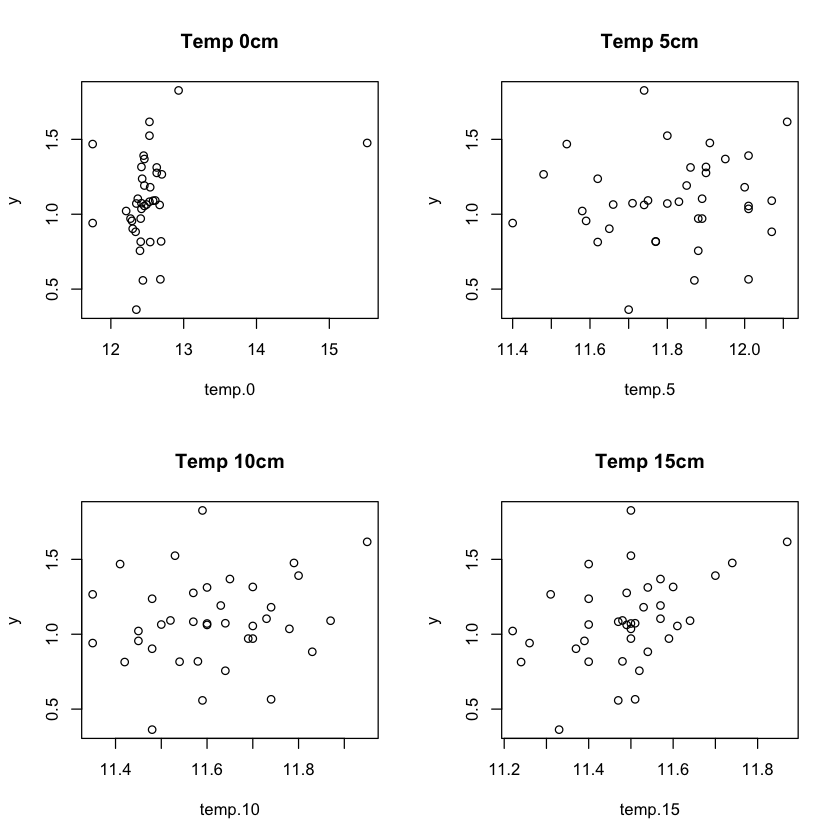

In [ ]:
#Temperatur vs Bodenatmung
par(mfrow=c(2,2))
plot(y ~ temp.0, hainich.data, main="Temp 0cm")
plot(y ~ temp.5, hainich.data, main="Temp 5cm")
plot(y ~ temp.10, hainich.data, main="Temp 10cm")
plot(y ~ temp.15, hainich.data, main="Temp 15cm")


- Temperaturen liegen etwa 12–13.5 °C
- An der Oberfläche ist die temperatur ≈ gleich und bodenatmung sehr unterschiedlich -> oberflächetemp erklärt y nicht gut -> sonne wind etc
- temp 5 cm -> mehr temp unterschiede, leichter steigung, ~ mehr temp mehr bodenarmung -> hier leben mikroorgnaismen
- temp 10 cm -> temp ist stabiler? postive zsmhg
- temp 15 -> positiver trend
- je tiefer desto klarer den zsmhg

- Bio: Höhere Temperatur → mehr mikrobielle Aktivität → mehr CO₂ → höhere Bodenatmung

- postiver zhmg, moderate korrelation aber viele punkte streuen dh temp ist nicht das einzige faktor!

In [ ]:
cor(y, hainich.data$temp.0)
cor(y, hainich.data$temp.5)
cor(y, hainich.data$temp.10)
cor(y, hainich.data$temp.15) # temp 5 hat die höchste korrelation! das benutzen wir 

[1] 0.2630299

[1] 0.08963092

[1] 0.1775612

[1] 0.4348038

[1] -0.259031

[1] 0.4741594

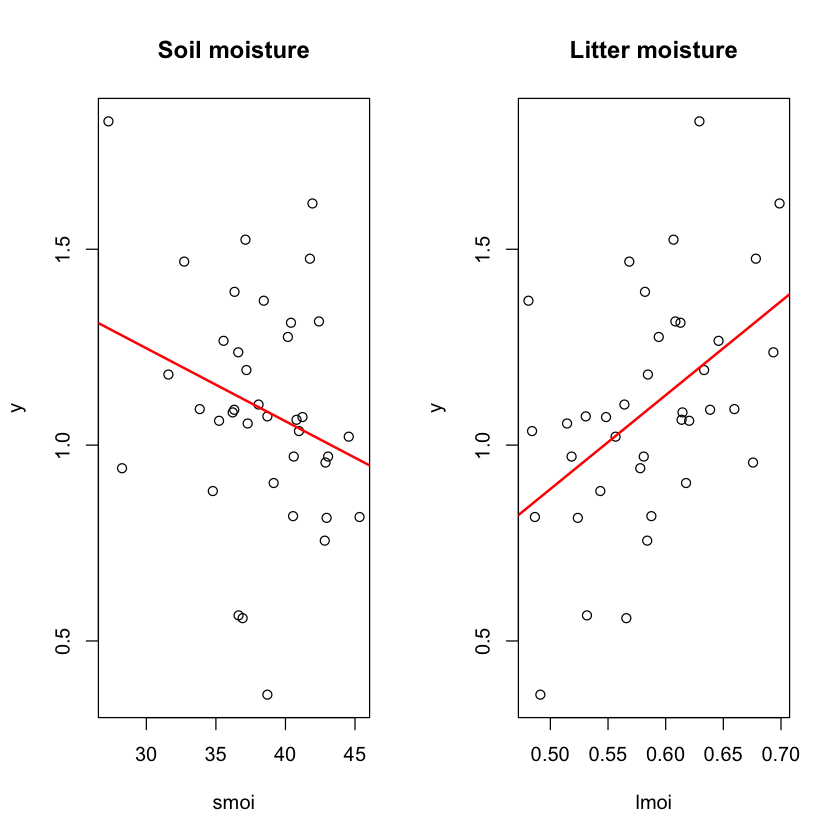

In [10]:
#Bodenfeuchte vs Bodenatmung
par(mfrow = c(1, 2))
plot(y ~ smoi, hainich.data, main="Soil moisture")
abline(lm(y ~ smoi, data=hainich.data), col= "red", lwd=2)
plot(y ~ lmoi, hainich.data, main="Litter moisture")
abline(lm(y ~ lmoi, data=hainich.data), col= "red", lwd=2)
cor(y, hainich.data$smoi)
cor(y, hainich.data$lmoi)

- smoi = soil moisture (Bodenfeuchte) 
	- Bodenatmung ist bei mittlerer Feuchte am höchsten
	- Bei sehr niedriger oder sehr hoher Feuchte eher niedrigere Werte ->  ∩-Form Parabel (QUADRATUSH!) ->  Lin MODELL NICHT GUT!!! (Siehe unten)

- lmoi = litter moisture (Feuchte der Streuschicht) 
	- Zusammenhang stärker als bei smoi
	- Bodenatmung stegt mit smoi, aber bei sehr hoher Feuchte wieder Streuung / evtl. Sättigung
	- Streuschicht ist wichtig Feuchte steuert Aktivität direkt (lmoi kann ein starker Prädiktor sein!!)

	#lIN MODELL NICHT GUT!!!

In [ ]:
lm(soil.res ~ smoi, data=hainich.data)
lm(soil.res ~ lmoi, data=hainich.data) #starker positive effekt
lm(soil.res ~ smoi + I(smoi^2), data=hainich.data)
lm(soil.res ~ lmoi + I(lmoi^2), data=hainich.data) #lineare zusammenhang, quadratische term veschiebt nur leicht 



Call:
lm(formula = soil.res ~ smoi, data = hainich.data)

Coefficients:
(Intercept)         smoi  
    5.81114     -0.07045  



Call:
lm(formula = soil.res ~ lmoi, data = hainich.data)

Coefficients:
(Intercept)         lmoi  
     -1.174        7.323  



Call:
lm(formula = soil.res ~ smoi + I(smoi^2), data = hainich.data)

Coefficients:
(Intercept)         smoi    I(smoi^2)  
  16.286727    -0.646660     0.007815  



Call:
lm(formula = soil.res ~ lmoi + I(lmoi^2), data = hainich.data)

Coefficients:
(Intercept)         lmoi    I(lmoi^2)  
       5.97       -17.32        21.04  


[1] 0.3065886

[1] -0.01774499

[1] 0.1389108

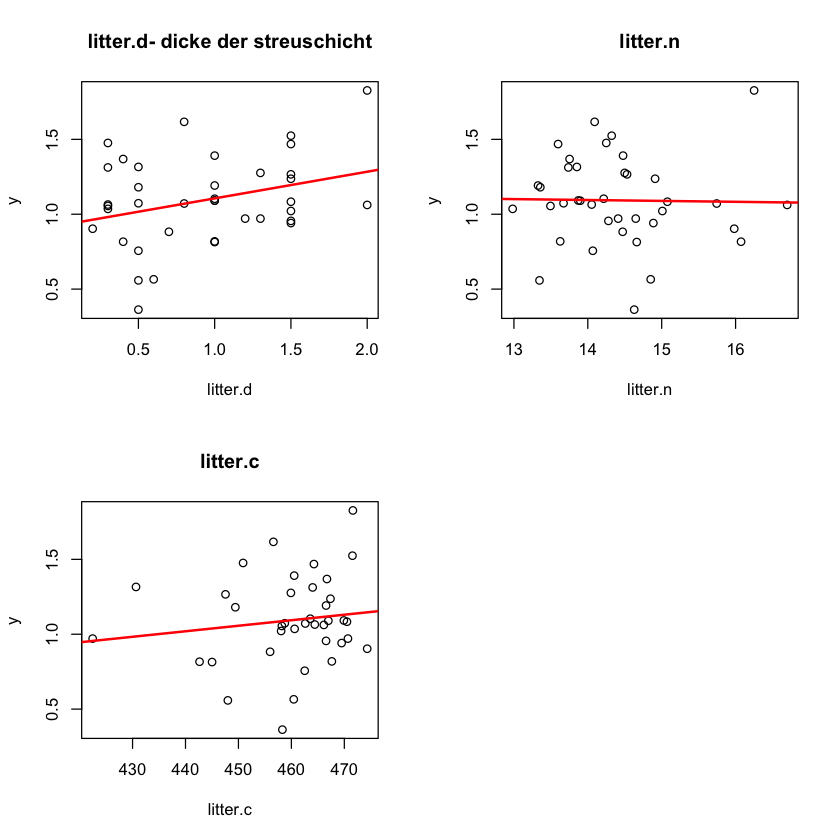

In [8]:
#-Litter- Streu (organisches Material. Residuos)

par(mfrow = c(2, 2))
plot(y ~ litter.d, hainich.data, main="litter.d- dicke der streuschicht")
abline(lm(y ~ litter.d, data=hainich.data), col="red", lwd=2)

plot(y ~ litter.n, hainich.data, main="litter.n")
abline(lm(y ~ litter.n, data=hainich.data), col= "red", lwd=2)

plot(y ~ litter.c, hainich.data, main="litter.c")
abline(lm(y ~ litter.c, data=hainich.data), col= "red", lwd=2)

cor(y, hainich.data$litter.d) #höher
cor(y, hainich.data$litter.n) #neg korrelation
cor(y, hainich.data$litter.c)

- litter.d = dicke der streuschicht
Bodenatmung steigt leicht mit zunehmender Dicke
- litter.n = Stickstoff in Streu 
kaum zusmmanehang, neg korrelation
- litter.c = Kohlenstoff in Streu 
kaum zusmmanehang
Fast alle Streu enthält viel Kohlenstoff.→ C ist selten limitierend.


[1] -0.04565831

[1] 0.1516593

[1] -0.1826854


Call:
lm(formula = y ~ ph.soil5, data = hainich.data)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.80124 -0.15870 -0.01886  0.18059  0.73784 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)   
(Intercept)   1.6392     0.4926   3.328  0.00203 **
ph.soil5     -0.1323     0.1187  -1.115  0.27229   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.2957 on 36 degrees of freedom
Multiple R-squared:  0.03337,	Adjusted R-squared:  0.006523 
F-statistic: 1.243 on 1 and 36 DF,  p-value: 0.2723


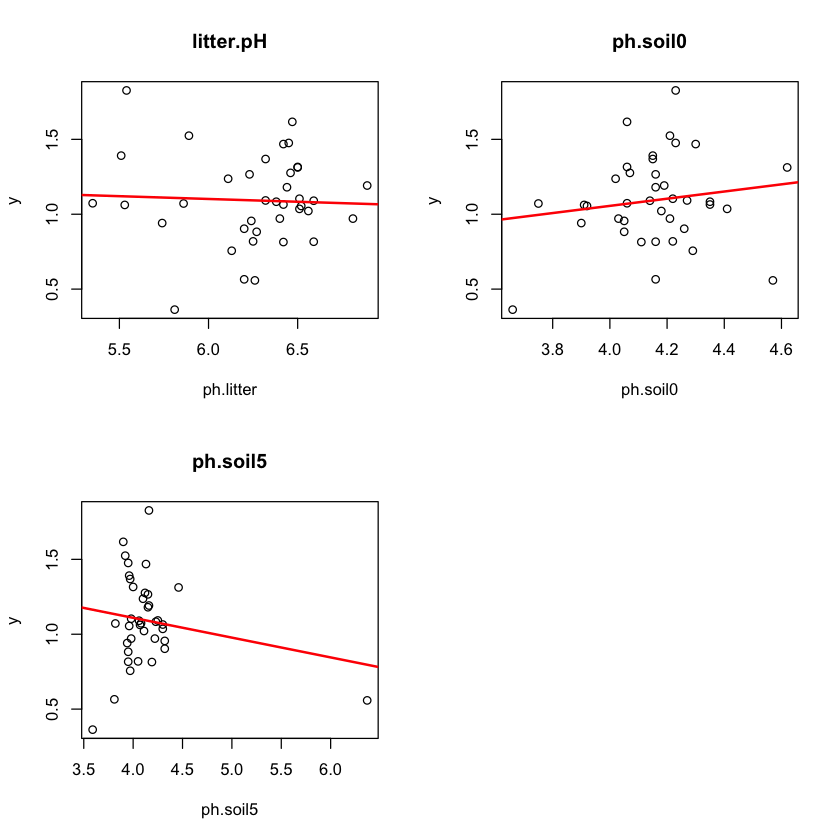

In [20]:
#-pH-Wert
par(mfrow = c(2, 2))
plot(y ~ ph.litter, hainich.data, main="litter.pH")
abline(lm(y ~ ph.litter, data=hainich.data), col= "red", lwd=2)
plot(y ~ ph.soil0, hainich.data, main="ph.soil0")
abline(lm(y ~ ph.soil0, data=hainich.data), col= "red", lwd=2)
plot(y ~ ph.soil5, hainich.data, main="ph.soil5")
abline(lm(y ~ ph.soil5, data=hainich.data), col= "red", lwd=2)

cor(y, hainich.data$ph.litter) #negative korrelation
cor(y, hainich.data$ph.soil0) # pos
cor(y, hainich.data$ph.soil5) #negative korrelation
summary(lm(y ~ ph.soil5, data=hainich.data))

- ph.litter → Streu
- ph.soil0 → Oberfläche
- ph.soil5 → 5 cm

- Mikroorganismen reagieren stark auf pH nur wenn der pH extrem ist.
- Typische Bereiche:
	- sehr sauer → Mikrobenaktivität sinkt
	- neutral → maximale Aktivität

Die Werte hier liegen ungefähr bei	pH 3.8 – 4.6 -> relativ konstant sauer.
Wenn der Bereich so klein ist, kann man keinen starken Effekt sehen.
pH erklärt nur einen kleinen Teil der Variation.

ph wert ist wichtig aber variiert hier im Datensatz zu wenig, um einen Effekt zu zeigen.


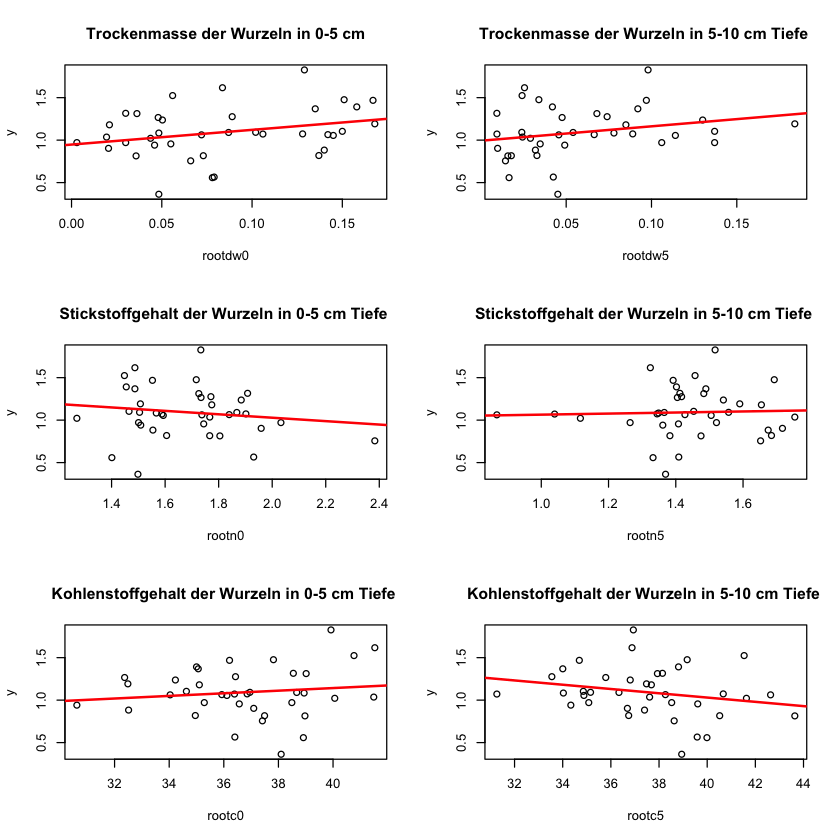

In [16]:
# Würzeln
par(mfrow=c(3,2))
plot(y ~ rootdw0, hainich.data, main="Trockenmasse der Wurzeln in 0-5 cm")
abline(lm(y ~ rootdw0, data=hainich.data), col= "red", lwd=2)
plot(y ~ rootdw5, hainich.data, main="Trockenmasse der Wurzeln in 5-10 cm Tiefe ")
abline(lm(y ~ rootdw5, data=hainich.data), col= "red", lwd=2)

plot(y ~ rootn0, hainich.data, main="Stickstoffgehalt der Wurzeln in 0-5 cm Tiefe ")
abline(lm(y ~ rootn0, data=hainich.data), col= "red", lwd=2)
plot(y ~ rootn5, hainich.data, main="Stickstoffgehalt der Wurzeln in 5-10 cm Tiefe ")
abline(lm(y ~ rootn5, data=hainich.data), col= "red", lwd=2)

plot(y ~ rootc0, hainich.data, main="Kohlenstoffgehalt der Wurzeln in 0-5 cm Tiefe ")
abline(lm(y ~ rootc0, data=hainich.data), col= "red", lwd=2)
plot(y ~ rootc5, hainich.data, main="Kohlenstoffgehalt der Wurzeln in 5-10 cm Tiefe ")
abline(lm(y ~ rootc5, data=hainich.data), col= "red", lwd=2)

In [ ]:
# Würzeln
cor(y, hainich.data$rootdw0) #hoher
cor(y, hainich.data$rootdw5)

cor(y, hainich.data$rootn0) #neg
cor(y, hainich.data$rootn5) #pos, höher

cor(y, hainich.data$rootc0)
cor(y, hainich.data$rootc5) #neg

[1] 0.2853238

[1] 0.2464194

[1] -0.1469047

[1] 0.03874725

[1] 0.1333129

[1] -0.2300238

-
-
-


[1] 0.3260894

[1] 0.2691148

[1] 0.2297989

[1] 0.2138516

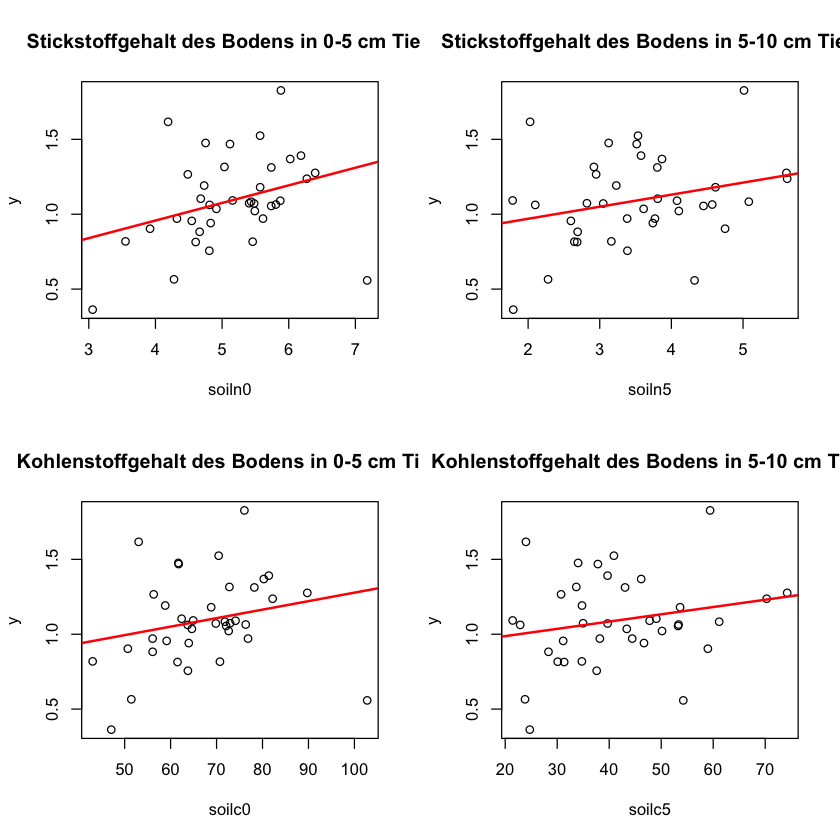

In [23]:
#Boden Nährstoffe

par(mfrow=c(2,2))
plot(y ~ soiln0, hainich.data, main=" Stickstoffgehalt des Bodens in 0-5 cm Tiefe")
abline(lm(y ~ soiln0, data=hainich.data), col= "red", lwd=2)
plot(y ~ soiln5, hainich.data, main=" Stickstoffgehalt des Bodens in 5-10 cm Tiefe")
abline(lm(y ~ soiln5, data=hainich.data), col= "red", lwd=2)
cor(y, hainich.data$soiln0)
cor(y, hainich.data$soiln5)

plot(y ~ soilc0, hainich.data, main=" Kohlenstoffgehalt des Bodens in 0-5 cm Tiefe")
abline(lm(y ~ soilc0, data=hainich.data), col= "red", lwd=2)
plot(y ~ soilc5, hainich.data, main=" Kohlenstoffgehalt des Bodens in 5-10 cm Tiefe")
abline(lm(y ~ soilc5, data=hainich.data), col= "red", lwd=2)
cor(y, hainich.data$soilc0)
cor(y, hainich.data$soilc5)

[1] 0.1629472

[1] -0.001182912

[1] -0.268061

[1] 0.1925123

[1] 0.07152196

[1] -0.001711134

[1] 0.2757346

[1] 0.1551852

[1] 0.2020148

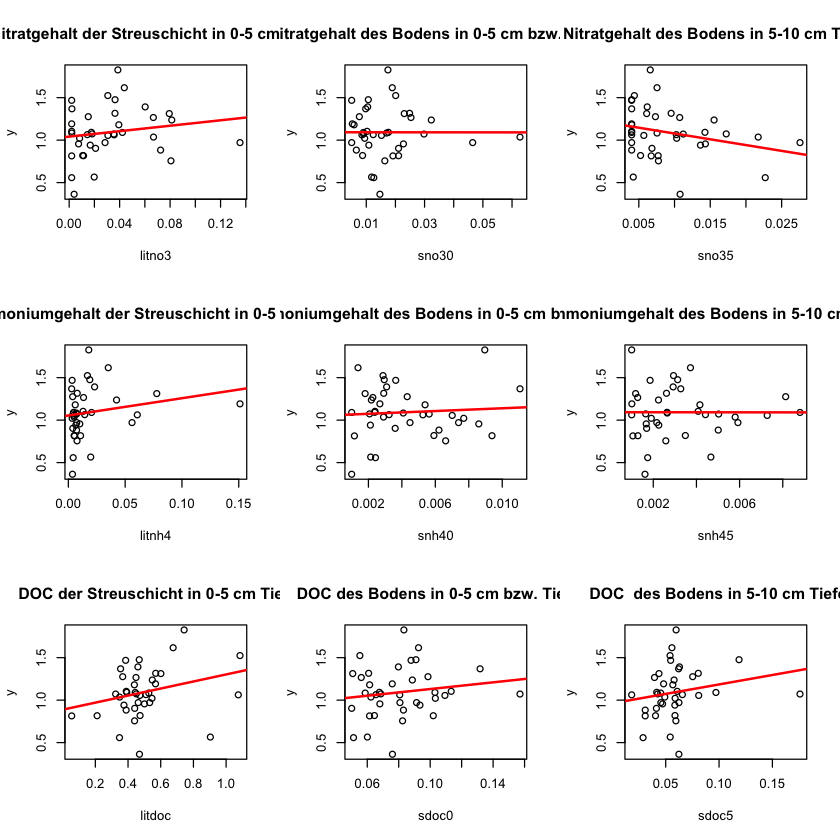

In [18]:
# Nährstoffe der Streuschicht bzw. des Bodens i
par(mfrow=c(3,3))


plot(y ~ litno3, hainich.data, main="Nitratgehalt der Streuschicht in 0-5 cm Tiefe")
abline(lm(y ~ litno3, data=hainich.data), col= "red", lwd=2)
plot(y ~ sno30, hainich.data, main="Nitratgehalt des Bodens in 0-5 cm bzw. Tiefe")
abline(lm(y ~ sno30, data=hainich.data), col= "red", lwd=2)
plot(y ~ sno35, hainich.data, main="Nitratgehalt des Bodens in 5-10 cm Tiefe")
abline(lm(y ~ sno35, data=hainich.data), col= "red", lwd=2)
cor(y, hainich.data$litno3)
cor(y, hainich.data$sno30)
cor(y, hainich.data$sno35)

plot(y ~ litnh4, hainich.data, main="Ammoniumgehalt der Streuschicht in 0-5 cm Tiefe")
abline(lm(y ~ litnh4, data=hainich.data), col= "red", lwd=2)
plot(y ~ snh40, hainich.data, main="Ammoniumgehalt des Bodens in 0-5 cm bzw. Tiefe")
abline(lm(y ~ snh40, data=hainich.data), col= "red", lwd=2)
plot(y ~ snh45, hainich.data, main="Ammoniumgehalt des Bodens in 5-10 cm Tiefe")
abline(lm(y ~ snh45, data=hainich.data), col= "red", lwd=2)
cor(y, hainich.data$litnh4)
cor(y, hainich.data$snh40)
cor(y, hainich.data$snh45)

plot(y ~ litdoc, hainich.data, main=" DOC der Streuschicht in 0-5 cm Tiefe")
abline(lm(y ~ litdoc, data=hainich.data), col= "red", lwd=2)
plot(y ~ sdoc0, hainich.data, main=" DOC des Bodens in 0-5 cm bzw. Tiefe")
abline(lm(y ~ sdoc0, data=hainich.data), col= "red", lwd=2)
plot(y ~ sdoc5, hainich.data, main=" DOC  des Bodens in 5-10 cm Tiefe")
abline(lm(y ~ sdoc5, data=hainich.data), col= "red", lwd=2)
cor(y, hainich.data$litdoc)
cor(y, hainich.data$sdoc0)
cor(y, hainich.data$sdoc5)

[1] -0.1518531

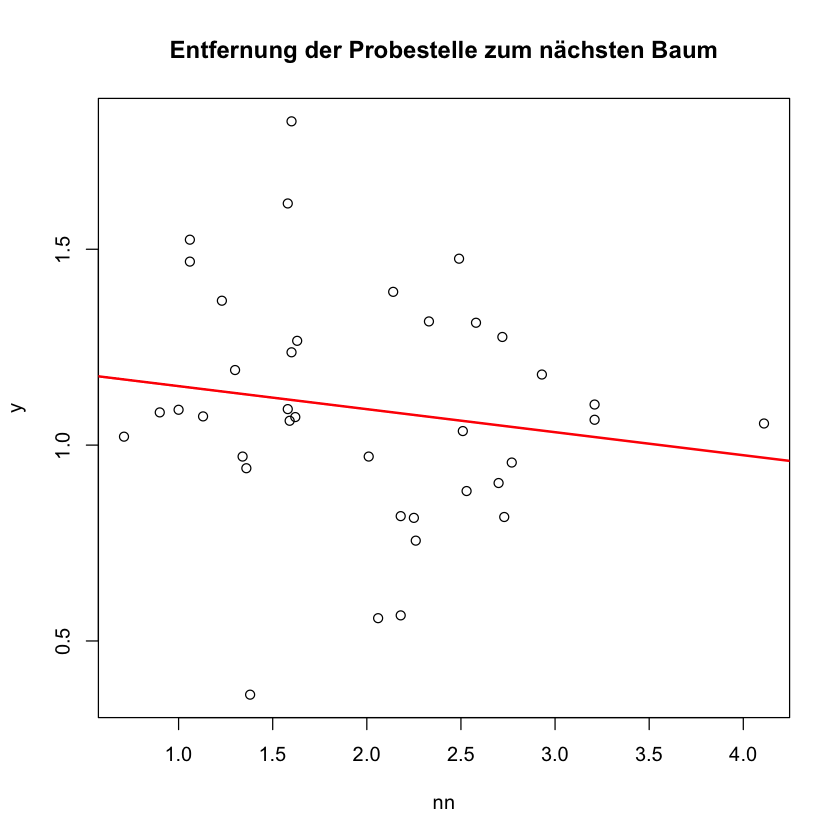

In [19]:
#nn – Entfernung der Probestelle zum nächsten Baum (nearest neighbour) 
plot(y ~ nn, hainich.data, main="Entfernung der Probestelle zum nächsten Baum")
abline(lm(y ~ nn, data=hainich.data), col= "red", lwd=2)
cor(y, hainich.data$nn)

- x-Achse → nn (Distanz zum nächsten Baum)
- y-Achse → Bodenatmung (soil.res)
- Die rote Linie fällt leicht nach rechts: negative trend -> größere Entfernung zum Baum → etwas geringere Bodenatmung. (ergibt sinn :) )
- effekt ist klein, punkte streuen stark
- Distanz zum Baum erklärt nur einen kleinen Teil der Variation der Bodenatmung.

### Korrelationen
- stärke messen
- Korrelationsmatrix
    - Welche Variablen sind linear verbunden?
    - korrelation von y mit einzelne variablen
    

In [ ]:
cor(y, hainich.data$smoi)
cor(y, hainich.data$lmoi)

[1] -0.259031

[1] 0.08963092

[1] 0.1775612

[1] 0.4348038

### stärkste Zusammenhänge (sortiert absteigenf)
- lmoi
- soiln0
- litter.d
- rootdw0
- litdoc
- smoi

### mittlere
- soiln5
- rootdw5
- soilc0
- soilc5
- -----------
-  rest irrelevant

### Wichtigste Einflussgrößen
siehe Zielvariable_vs_Einflussgroßen.md
Wir sollten 3–5 Variablen im Modell haben :s

- tem.5 Temperatur 5 zeigt stärkste korrelation als die anderen aber vielleicht nicht so wichtig und sie korreliert teilweise mit feuchte, so es reicht wenn wir nur feuchte nehmen? es wäre redundant sonst RAUS
- smoi -> scheint nicht so wichtig zu sein (seieh unten)
- lmoi stärskte korrelation
- sno35 schenint wichtig zu sein ? (Nitratgehalt des Bodens in 5-10 cm Tiefe)
- litter.c Kohlenstoff in Streu scheint auch wichtig
- litdoc zeigt das stärkste effekt mitnehemn (DOC der Streuschicht in 0-5 cm)
- rootdw0  Trockenmasse der Wurzeln in 0-5 cm rootdw0 -> (feine wurzel hier wahrscheinlich)korreliert besser als bei 5.10 cm (1)
- soil0? 

- Boden Nährstoffe (C-N) -> weiß ich nicht


- lmoi, rootdw0, litdoc scheinend seht wichtig zu sein

# Modell 
- Welches Modell, warum?

In [42]:
y <- log(hainich.data$soil.res)

full_model <- lm(y ~ lmoi + smoi + rootdw0 + litdoc + soiln0 + sno35,
                 data = hainich.data)

summary(full_model)


Call:
lm(formula = y ~ lmoi + smoi + rootdw0 + litdoc + soiln0 + sno35, 
    data = hainich.data)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.59293 -0.15283 -0.00272  0.15560  0.40119 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)  
(Intercept) -0.452975   0.707335  -0.640   0.5266  
lmoi         1.934272   0.749377   2.581   0.0148 *
smoi        -0.006063   0.010563  -0.574   0.5702  
rootdw0      1.012608   0.956015   1.059   0.2977  
litdoc       0.174072   0.234234   0.743   0.4630  
soiln0       0.103767   0.051158   2.028   0.0512 .
sno35       -6.645241   8.010322  -0.830   0.4131  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.2486 on 31 degrees of freedom
Multiple R-squared:  0.4116,	Adjusted R-squared:  0.2978 
F-statistic: 3.615 on 6 and 31 DF,  p-value: 0.007809


- Modell erklärt 41% der Variation der Bodenatmung.
- sno35 scheint hier keine rolle zu spielen 
- viele scheinen auch irrelevant!

### Quadratische term für smoi
- leicht besser aber dann haben wir mehr parametern, es lohn sich nicht (siehe model2)

In [41]:
model2 <- lm(y ~ lmoi + smoi + I(smoi^2) + rootdw0 + litdoc + soiln0 + sno35,
             data = hainich.data)

summary(model2)


Call:
lm(formula = y ~ lmoi + smoi + I(smoi^2) + rootdw0 + litdoc + 
    soiln0 + sno35, data = hainich.data)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.54453 -0.15644 -0.00729  0.15239  0.36751 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)  
(Intercept)  2.939736   2.464294   1.193   0.2422  
lmoi         1.911595   0.737060   2.594   0.0145 *
smoi        -0.196425   0.133054  -1.476   0.1503  
I(smoi^2)    0.002598   0.001811   1.435   0.1616  
rootdw0      1.350838   0.969179   1.394   0.1736  
litdoc       0.237866   0.234582   1.014   0.3187  
soiln0       0.100927   0.050345   2.005   0.0541 .
sno35       -5.323628   7.930499  -0.671   0.5072  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.2444 on 30 degrees of freedom
Multiple R-squared:  0.4494,	Adjusted R-squared:  0.321 
F-statistic: 3.499 on 7 and 30 DF,  p-value: 0.007331


### model final

In [44]:
model_final <- lm(y ~ lmoi + soiln0 + rootdw0, data = hainich.data)
summary(model_final)


Call:
lm(formula = y ~ lmoi + soiln0 + rootdw0, data = hainich.data)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.68060 -0.16139 -0.01761  0.14613  0.49775 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)   
(Intercept) -0.87156    0.46834  -1.861  0.07141 . 
lmoi         2.29398    0.68940   3.327  0.00211 **
soiln0       0.09795    0.04962   1.974  0.05654 . 
rootdw0      1.40045    0.83646   1.674  0.10326   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.2457 on 34 degrees of freedom
Multiple R-squared:  0.3696,	Adjusted R-squared:  0.314 
F-statistic: 6.644 on 3 and 34 DF,  p-value: 0.001186


- erklärt 37% der variation der bodenatnmzbg 
-rootdw0 nicht statistik signifikant ?????